# Final exam: Math Concepts For Developers #


# Can a robot ignore air resistance when shooting a basketball? #

*Made by: Georgi Ilkov*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Introduction ##

Imagine a robot plays basketball. To make the shot, it has to calculate how fast and at what angle to release the ball. The simplest way to calculate it is to use the projectile formula from school physics.

However, the formula assumes that while making the shot, the ball faces **no air**. The real basketball flies through the air, and the air slows it down. The rim leaves only a few centimeters of room for error, so a small difference could turn the shot into a miss.

**Research question:** *If the robot shoots using the no-air formula, will the ball still go in?*

To answer this question, I will:
1. Build an **ideal model** of the shot without any air resistance and derive the angle needed to hit the hoop.
2. Build a **real model** with air resistance. The equations cannot be solved on paper, so I will simulate it using **Euler's method**.
3. Let the robot aim with the ideal model, simulate the shot with the real model and measure how far the ball misses the center of the hoop.


| Quantity | Value |
|---|---|
| Release height | 2.00 m |
| Hoop height | 3.05 m |
| Free-throw distance | 4.60 m |
| Three-point distance | 6.75 m |
| Ball mass | 0.62 kg |
| Ball diameter | 0.24 m |
| Rim diameter | 0.45 m |

## 2. The ideal model (no air resistance)

### 2.1 Assumptions
- The only force acting on the ball is **gravity**, $g = 9.81\ \text{m/s}^2$.
- The ball is treated as a point: we ignore its size and spin.
- The robot releases the ball from the origin $(0, 0)$ with speed $v_0$ at angle $\theta$ above the horizontal.

We place the origin at the release point. The hoop is at $(x_h, y_h)$ then, where $y_h = 3.05 - 2.00 = 1.05$ m.

$x_h$ - the horizontal distance to the hoop (4.60 m for a free throw, 6.75 m for a three-pointer).

### 2.2 Equations of motion
Gravity acts only downwards, so:
- the **horizontal** velocity $v_0\cos\theta$ never changes,
- the **vertical** velocity $v_0\sin\theta$ decreases by $g$ every second.

This gives position of the ball at time $t$:

$$x(t) = v_0\cos\theta \cdot t \qquad\qquad y(t) = v_0\sin\theta \cdot t - \frac{1}{2} g t^2$$

In [2]:
G = 9.81 # m/s^2
HOOP_HEIGHT = 1.05 # Height of the hoop above the release point, m
FREE_THROW = 4.60 # horizontal distance to the hoop from the free-throw line, m
THREE_POINT = 6.75 # horizontal distance to the hoop from the three-throw line, m

### 2.3 The path is a parabola
From the equation of $x(t)$ we can express the time: 
$$t = \frac{x}{v_0\cos\theta}$$

Substituting it into $y(t)$ removes $t$ and gives the height as a function of the horizontal distance:

$$y(x) = x\tan\theta - \frac{g\,x^2}{2v_0^2\cos^2\theta}$$

This is a quadratic function of $x$ with a negative coefficient in front of $x^2$, so the path of the ball is a **parabola opening downward**.

In [3]:
def ideal_y(x, v0, theta_deg):
# Height of the ball (m) at horizontal distance x in the no-air model. 

    theta = np.radians(theta_deg)
    return x * np.tan(theta) - G * x**2 / (2 * v0**2 * np.cos(theta)**2)

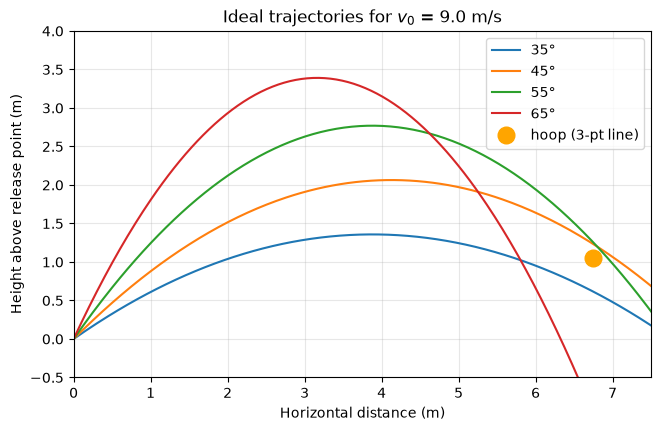

In [4]:
x = np.linspace(0, 7.5, 300)
v0 = 9.0

plt.figure(figsize=(8, 4.5))
for angle in [35, 45, 55, 65]:
    plt.plot(x, ideal_y(x, v0, angle), label=f"{angle}°")

plt.plot(6.75, HOOP_HEIGHT, 'o', color = 'orange', markersize = 12, label = 'hoop (3-pt line)')
plt.xlim(0, 7.5)
plt.ylim(-0.5, 4)
plt.gca().set_aspect("equal")
plt.xlabel("Horizontal distance (m)")
plt.ylabel("Height above release point (m)")
plt.title(f'Ideal trajectories for $v_0$ = {v0} m/s')
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

In the graph we can see that none of the shots goes exactly through the hoop. The shots at 45° and 55° are the closest, but both pass slightly **above** it, while the shots at 35° and 65° pass **below** it.

This means that the correct angle must lie between a shot that passes below the hoop and one that passes above it. The interesting result is that there are **two** correct answers:
- between **35° and 45°**: a flatter, lower arc,
- between **55° and 65°**: a higher arc.

In the next section we calculate these two angles exactly.

### 2.4 Which angle hits the hoop?
We want the path to pass through the hoop, so we set $x = x_h$ and $y = y_h$ in the parabola equation:

$$y_h = x_h\tan\theta - \frac{g\,x_h^2}{2v_0^2\cos^2\theta}$$

This equation contains both $\tan\theta$ and $\cos\theta$. Using the identity $\dfrac{1}{\cos^2\theta} = 1 + \tan^2\theta$, we can write everything in terms of $u = \tan\theta$:

$$y_h = x_h\,u - \frac{g\,x_h^2}{2v_0^2}\,(1 + u^2)$$

Multiplying both sides by $2v_0^2$ and moving everything to one side gives a **quadratic equation in $u$**:

$$g\,x_h^2\,u^2 - 2v_0^2\,x_h\,u + \left(g\,x_h^2 + 2v_0^2\,y_h\right) = 0$$

Solving it with the quadratic formula:

$$\tan\theta = \frac{v_0^2 \pm \sqrt{v_0^4 - g\left(g\,x_h^2 + 2\,y_h\,v_0^2\right)}}{g\,x_h}$$

The sign of the discriminant $D = v_0^4 - g\left(g\,x_h^2 + 2\,y_h\,v_0^2\right)$ tells us how many solutions there are:

- $D > 0$: **two angles** hit the hoop: a flatter shot ($-$) and a higher arc ($+$). This explains the two answers we saw in the plot.
- $D = 0$: exactly **one** angle. This happens at the minimum speed needed to reach the hoop.
- $D < 0$: **no angle** works. The hoop is out of reach at this speed.

In [5]:
def angles_to_hit(v0, x_target, y_target):
    """Return the (low, high) release angles in degrees that hit the target.

    Returns None if the target cannot be reached with speed v0.
    """

    discriminant = v0**4 - G * (G * x_target**2 + 2 * y_target * v0**2)
    if discriminant < 0:
        return None

    root = np.sqrt(discriminant)
    low = np.degrees(np.arctan((v0**2 - root) / G / x_target))
    high = np.degrees(np.arctan((v0**2 + root) / G / x_target))
    return low, high

In [6]:
for name, distance in(["Free throw", FREE_THROW], ["Three-pointer", THREE_POINT]):
    for v0 in [7.0, 8.0, 9.0]:
        result = angles_to_hit(v0, distance, HOOP_HEIGHT)
        if result is None:
            print(f"{name:13} v0 = {v0} m/s -> out of reach")
        else:
            print(f"{name:13} v0 = {v0} m/s -> {result[0]:5.1f}° or {result[1]:5.1f}°")

Free throw    v0 = 7.0 m/s -> out of reach
Free throw    v0 = 8.0 m/s ->  39.2° or  63.7°
Free throw    v0 = 9.0 m/s ->  31.4° or  71.4°
Three-pointer v0 = 7.0 m/s -> out of reach
Three-pointer v0 = 8.0 m/s -> out of reach
Three-pointer v0 = 9.0 m/s ->  41.4° or  57.4°


At **7 m/s** the robot cannot reach the hoop even from the free-throw line, because the discriminant is negative. At higher speed two angles appear and they move further apart as the speed increases.

For the three-pointer at **9 m/s**, the angles are **41.4°** and **57.4°**. This confirms the prediction from the plot: one lies between 35° and 45°, the other between 55° and 65°. Everything is going smoothly and as *predicted*.

### 2.5 Checking the formula
To check the formula we put the computed angles into $y(x)$. At the hoop's distance $x_h$, the height of the ball should be exactly the hoop's height $y_h$.

In [7]:
v0 = 9.0 # release speed, m/s
low, high = angles_to_hit(v0, THREE_POINT, HOOP_HEIGHT)

for angle in low, high:
    error = ideal_y(THREE_POINT, v0, angle) - HOOP_HEIGHT
    print(f"angle{angle:5.1f}° -> height error at the hoop: {error:.2e} m")

angle 41.4° -> height error at the hoop: -1.11e-15 m
angle 57.4° -> height error at the hoop: -2.89e-15 m


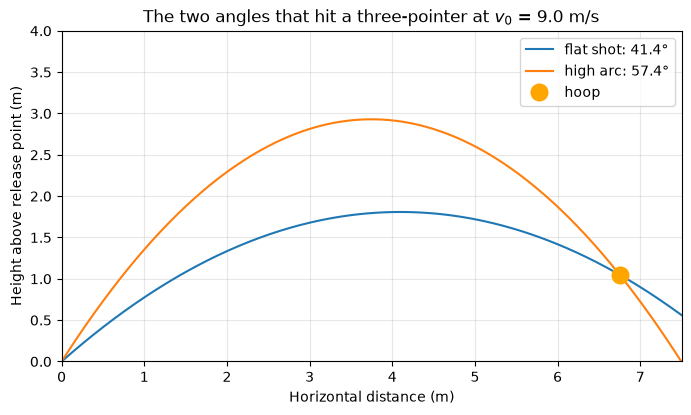

In [9]:
x = np.linspace(0, 7.5, 300)

plt.figure(figsize=(8, 4.5))
plt.plot(x, ideal_y(x, v0, low), label=f"flat shot: {low:.1f}°")
plt.plot(x, ideal_y(x, v0, high), label=f"high arc: {high:.1f}°")
plt.plot(THREE_POINT, HOOP_HEIGHT, "o", color="orange", markersize=12, label="hoop")
plt.xlim(0, 7.5)
plt.ylim(0, 4)
plt.gca().set_aspect("equal")
plt.xlabel("Horizontal distance (m)")
plt.ylabel("Height above release point (m)")
plt.title(f"The two angles that hit a three-pointer at $v_0$ = {v0} m/s")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2.6 Summary of the ideal model
- Without air resistance, the path of the ball is a parabola.
- Finding the angle that hits the hoop leads to a **quadratic equation** in $\tan\theta$. Its discriminant tells us how many solutions there are - two, one or none.
- For a three-pointer at 9 m/s, the two angles are **41.4°** and **57.4°**. Putting them back into the parabola gives a height error of order $10^{-15}$ m, so the formula is correct.

However, these angles are if the is **no air**, so in the next step we will check how the shots are made and calculate them with *air resistance*.